# UTS Graf Sains Data

| | |
|---|---|
| **Nama** | Rizqika Naura Fuady |
| **NIM** | 23031554120 |
| **Kelas** | Graf Sains Data 2023A |
| **Dataset** | RetailRocket e-commerce dataset (`events.csv`), Kaggle |
| **Periode P1 (training)** | 2015-06-08 00:00:00 – 2015-07-05 23:59:59.999 UTC (`1433721600000` – `1436140799999`) |
| **Periode P2 (testing)** | 2015-07-06 00:00:00 – 2015-07-19 23:59:59.999 UTC (`1436140800000` – `1437350399999`) |

# 1. Tugas Pendahuluan
## 1.1 Persiapan dan Perkenalan Lingkungan

Virtual environment dibuat dan diaktifkan di Windows PowerShell (`source myvenv/bin/activate` pada soal hanya berlaku untuk Linux/MacOS):

```powershell
python -m venv myvenv
myvenv\Scripts\activate
pip install neo4j pandas numpy scipy scikit-learn networkx matplotlib tqdm jupyter
```

**Modifikasi dependensi:** `requirements.txt` pada soal memuat spesifikasi yang saling bertentangan (`neo4j>=4.0,<4.3` dan `neo4j==4.2.1`). Selain itu, `driver.execute_query()` dan `RoutingControl` pada tutorial 1.2 baru tersedia di driver Neo4j 5.x ke atas, sedangkan server yang digunakan adalah Neo4j 2026.09. Oleh karena itu digunakan driver Neo4j terbaru (6.4.1). Sel berikut memverifikasi bahwa kernel berjalan dari virtual environment `myvenv`.

In [1]:
import sys
print(sys.executable)

D:\semester 7\Graf Sains Data\UTS GSD\myvenv\Scripts\python.exe


In [2]:
import os, sys, random, getpass, time
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import networkx as nx
from networkx.algorithms import bipartite
from sklearn.preprocessing import normalize
from tqdm.auto import tqdm
import neo4j
from neo4j import GraphDatabase, RoutingControl

print("neo4j driver:", neo4j.__version__)

neo4j driver: 6.4.1


In [3]:
URI = "neo4j://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = getpass.getpass("Password Neo4j: ")

DB_TUTORIAL = "neo4j"
DB = "retailrocket"
DATA_DIR = "data"
NIM = 23031554120

P1 = (1433721600000, 1436140799999)   # 2015-06-08 00:00:00 – 2015-07-05 23:59:59.999 UTC
P2 = (1436140800000, 1437350399999)   # 2015-07-06 00:00:00 – 2015-07-19 23:59:59.999 UTC

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))
driver.verify_connectivity()
print("Koneksi berhasil")

def q(cypher, db=DB, **params):
    """Jalankan Cypher via Python API, hasil berupa DataFrame."""
    return driver.execute_query(cypher, parameters_=params, database_=db,
                                result_transformer_=neo4j.Result.to_df)

Password Neo4j:  ········


Koneksi berhasil


## 1.2 Mempelajari Penggunaan Driver Neo4j

In [4]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_=DB_TUTORIAL,
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_=DB_TUTORIAL, routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

add_friend(driver, "Arthur", "Guinevere")
add_friend(driver, "Arthur", "Lancelot")
add_friend(driver, "Arthur", "Merlin")
print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


### Pertanyaan Pendahuluan (Checkpoint)

**1. Apa nama database yang digunakan pada tutorial ini?**
Database **`neo4j`**, yaitu database bawaan setiap instance Neo4j, ditentukan melalui parameter `database_="neo4j"` pada `execute_query()`.

**2. Sebutkan akses lain (seperti sintaks DDL/DML Cypher) yang dapat digunakan untuk mengakses database lain dalam 1 instance!**
- Klausa Cypher `USE <nama_db>` di awal query, misalnya `USE retailrocket MATCH (n) RETURN count(n)`.
- Perintah Neo4j Browser/Query `:use <nama_db>` untuk berpindah database aktif.
- Pada driver Python: parameter `database_="<nama_db>"` pada `execute_query()` atau `driver.session(database="<nama_db>")`.
- Perintah administrasi (DDL) yang dijalankan pada database `system`: `SHOW DATABASES`, `CREATE DATABASE`, `START DATABASE`, `STOP DATABASE`, dan `DROP DATABASE`.

**3. Apa jenis graf pertemanan yang telah dibuat di sini?**
Graf **berarah (directed)** dan **tidak berbobot (unweighted)**: relasi `KNOWS` memiliki arah dari Arthur ke temannya dan tidak memiliki properti bobot. Strukturnya berbentuk **star graph**, dengan Arthur sebagai pusat (out-degree 3) yang terhubung ke Guinevere, Lancelot, dan Merlin (masing-masing in-degree 1). Karena `MERGE` digunakan, grafnya juga **sederhana**, yaitu tanpa busur ganda maupun self-loop.

In [5]:
s = driver.execute_query("MATCH (n) DETACH DELETE n", database_=DB_TUTORIAL).summary
print("Simpul terhapus:", s.counters.nodes_deleted,
      "| Relasi terhapus:", s.counters.relationships_deleted)

Simpul terhapus: 4 | Relasi terhapus: 3


## 1.3 Impor Data RetailRocket ke Neo4j

In [6]:
driver.execute_query(f"CREATE DATABASE {DB} IF NOT EXISTS WAIT", database_="system")
q("SHOW DATABASES YIELD name, currentStatus RETURN name, currentStatus", db="system")

,name,currentStatus
0,movie,online
1,neo4j,online
2,retailrocket,online
3,system,online


In [7]:
csv_file_path = os.path.join(DATA_DIR, "events.csv")
if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)

events = pd.read_csv(csv_file_path)
print(events.shape)
display(events.head())
rentang = events["timestamp"].agg(["min", "max"])
print(rentang.to_dict())
print(pd.to_datetime(rentang, unit="ms", utc=True).to_dict())
display(events["event"].value_counts())

(2756101, 5)


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


{'min': 1430622004384, 'max': 1442545187788}
{'min': Timestamp('2015-05-03 03:00:04.384000+0000', tz='UTC'), 'max': Timestamp('2015-09-18 02:59:47.788000+0000', tz='UTC')}


event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

## 2.1 Wrangling dan EDA
### No. 1–2 — Penentuan periode dan filter timestamp

| Fold | Peran | Rentang (UTC) | UNIX timestamp (ms) |
|---|---|---|---|
| P1 | Training | 2015-06-08 00:00:00 – 2015-07-05 23:59:59.999 | 1433721600000 – 1436140799999 |
| P2 | Testing | 2015-07-06 00:00:00 – 2015-07-19 23:59:59.999 | 1436140800000 – 1437350399999 |

**Alasan pemilihan periode:**
1. Dataset RetailRocket hanya mencakup 3 Mei – 18 September 2015, sehingga periode dipilih di dalam rentang tersebut.
2. P1 (4 minggu) lebih panjang agar data interaksi cukup kaya untuk mempelajari similarity antar-simpul, sedangkan P2 (2 minggu) cukup sebagai ground truth evaluasi. Rasio 2:1 (≈ 67:33) setara pembagian train/test yang umum.
3. P2 diletakkan tepat setelah P1 tanpa irisan, sehingga evaluasi mensimulasikan kondisi nyata (model dilatih dari data masa lalu, diuji pada perilaku waktu dekat berikutnya) dan mencegah data leakage.
4. Timestamp dataset berformat milidetik (13 digit), sehingga batas akhir memakai .999 agar seluruh event pada detik terakhir ikut tercakup.

Filter diterapkan dengan `Series.between()` (inklusif di kedua ujung), lalu hasilnya disimpan sebagai `data/events_p1.csv` dan `data/events_p2.csv`.

In [8]:
p1 = events[events["timestamp"].between(*P1)].copy()
p2 = events[events["timestamp"].between(*P2)].copy()
p1.to_csv(os.path.join(DATA_DIR, "events_p1.csv"), index=False)
p2.to_csv(os.path.join(DATA_DIR, "events_p2.csv"), index=False)

def ringkas(nama, df):
    w = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
    return {"fold": nama, "awal": w.min(), "akhir": w.max(), "event": len(df),
            "visitor": df["visitorid"].nunique(), "item": df["itemid"].nunique(),
            **df["event"].value_counts().to_dict()}

display(pd.DataFrame([ringkas("P1", p1), ringkas("P2", p2)]).set_index("fold"))
print("Visitor di P1 & P2:", len(set(p1.visitorid) & set(p2.visitorid)))

,awal,akhir,event,visitor,item,view,addtocart,transaction
fold,,,,,,,,
P1,2015-06-08 00:00:03.362000+00:00,2015-07-05 23:59:53.436000+00:00,558749,288382,112681,540182,13974,4593
P2,2015-07-06 00:00:06.443000+00:00,2015-07-19 23:59:52.377000+00:00,314088,178131,84647,303877,7650,2561


Visitor di P1 & P2: 9608


### Impor data P1 ke Neo4j (mekanisme batch)

Hanya **P1** yang diimpor sebagai graf training; P2 disimpan sebagai CSV untuk evaluasi rekomendasi.

**Model graf** (bipartit berarah): `(:Visitor)-[:VIEWED {timestamp}]->(:Item)`, `(:Visitor)-[:ADDED_TO_CART {timestamp}]->(:Item)`, `(:Visitor)-[:BOUGHT {timestamp, transactionId}]->(:Item)`. Setiap event menjadi satu busur, sehingga satu pasangan visitor–item bisa memiliki lebih dari satu busur.

**Modifikasi dari kode soal:**
1. Subquery `CALL { ... UNION ALL ... }` pada soal tidak valid di Neo4j 5+ (subquery penulisan tanpa `RETURN` tidak bisa digabung dengan `UNION`, dan `WITH` di awal `CALL` sudah deprecated). Percabangan per jenis event diganti dengan pola **`FOREACH` + `CASE`**: list `[1]` jika kondisi terpenuhi (busur dibuat sekali) dan `[]` jika tidak.
2. `transactionid` (bertipe float karena NaN) dikonversi dengan `str(int(x))` agar tersimpan sebagai `"4000"`, bukan `"4000.0"`.
3. Database dikosongkan terlebih dahulu (`DETACH DELETE` bertahap dengan `IN TRANSACTIONS`) agar impor ulang tidak menggandakan busur, karena busur dibuat dengan `CREATE`.
4. Uniqueness constraint pada `Visitor.visitorId` dan `Item.itemId` sekaligus membentuk indeks, sehingga `MERGE` tidak melakukan full scan.
5. Data dipotong per 10.000 baris dengan `iloc` (batch_size = 10.000), dan setiap batch ditulis dalam satu transaksi melalui `session.execute_write()`.

In [9]:
IMPORT_QUERY = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
FOREACH (_ IN CASE WHEN row.event = 'view' THEN [1] ELSE [] END |
    CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i))
FOREACH (_ IN CASE WHEN row.event = 'addtocart' THEN [1] ELSE [] END |
    CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i))
FOREACH (_ IN CASE WHEN row.event = 'transaction' THEN [1] ELSE [] END |
    CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i))
"""

def reset_database(session):
    session.run("MATCH (n) CALL (n) { DETACH DELETE n } IN TRANSACTIONS OF 10000 ROWS").consume()

def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE").consume()
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE").consume()

def import_batch(tx, batch):
    tx.run(IMPORT_QUERY, batch=batch).consume()

batch_size = 10_000
data_import = p1[["timestamp", "visitorid", "event", "itemid", "transactionid"]].copy()
data_import["transactionid"] = data_import["transactionid"].apply(
    lambda x: str(int(x)) if pd.notna(x) else "")
total_rows = len(data_import)
total_chunks = (total_rows // batch_size) + 1

t0 = time.time()
with driver.session(database=DB) as session:
    reset_database(session)
    create_constraints(session)
    print("Memulai proses impor data ke Neo4j...")
    for start in tqdm(range(0, total_rows, batch_size), total=total_chunks, desc="Mengimpor Batch Data"):
        session.execute_write(import_batch, data_import.iloc[start:start+batch_size].to_dict("records"))
print(f"Proses impor berhasil: {total_rows:,} event dalam {time.time()-t0:.1f} detik.")

Memulai proses impor data ke Neo4j...


Mengimpor Batch Data:   0%|          | 0/56 [00:00<?, ?it/s]

Proses impor berhasil: 558,749 event dalam 73.3 detik.


### No. 3 — Komposisi subgraph dengan Python API

**Penjelasan Cypher yang digunakan:**
- `MATCH (n)` mencocokkan seluruh simpul pada database `retailrocket`.
- `labels(n)` mengembalikan list label simpul. Karena setiap simpul hanya memiliki satu label (`Visitor` atau `Item`), elemen pertama `labels(n)[0]` dipakai sebagai jenis simpul.
- `count(*)` adalah fungsi agregasi. Pada Cypher, kolom non-agregat di `RETURN` (`jenis_simpul`) otomatis menjadi kunci pengelompokan (setara `GROUP BY` pada SQL), sehingga dihasilkan jumlah simpul per label.
- `MATCH ()-[r]->()` mencocokkan seluruh relasi berarah, lalu `type(r)` mengambil tipe relasinya (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`) dan dihitung per tipe dengan pola yang sama.
- `ORDER BY jumlah DESC` mengurutkan dari jumlah terbesar.
- Query dijalankan dari Python melalui `driver.execute_query()` dengan `result_transformer_=neo4j.Result.to_df`, sehingga hasilnya langsung berupa DataFrame. Hasilnya divalidasi silang dengan jumlah visitor unik, item unik, dan jumlah event pada `events_p1.csv`.

**Interpretasi:**
Subgraph P1 terdiri atas **401.063 simpul** (288.382 `Visitor` dan 112.681 `Item`) serta **558.749 relasi** (540.182 `VIEWED` atau 96,7%, 13.974 `ADDED_TO_CART` atau 2,5%, dan 4.593 `BOUGHT` atau 0,8%). Graf ini bersifat **bipartit** (relasi hanya dari Visitor ke Item) dan **berarah**. Dominasi `VIEWED` menunjukkan funnel e-commerce yang sangat menyempit dari melihat ke membeli: hanya sekitar 0,85% interaksi yang berakhir dengan pembelian.

In [10]:
komposisi_simpul = q("""
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah
ORDER BY jumlah DESC""")
komposisi_relasi = q("""
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(*) AS jumlah
ORDER BY jumlah DESC""")
display(komposisi_simpul, komposisi_relasi)

validasi = pd.DataFrame({
    "Neo4j": [int(komposisi_simpul.set_index("jenis_simpul").loc["Visitor", "jumlah"]),
              int(komposisi_simpul.set_index("jenis_simpul").loc["Item", "jumlah"]),
              int(komposisi_relasi["jumlah"].sum())],
    "pandas (P1)": [p1.visitorid.nunique(), p1.itemid.nunique(), len(p1)],
}, index=["Visitor", "Item", "Total relasi"])
validasi["cocok"] = validasi["Neo4j"] == validasi["pandas (P1)"]
display(validasi)

,jenis_simpul,jumlah
0,Visitor,288382
1,Item,112681


,jenis_relasi,jumlah
0,VIEWED,540182
1,ADDED_TO_CART,13974
2,BOUGHT,4593


,Neo4j,pandas (P1),cocok
Visitor,288382,288382,True
Item,112681,112681,True
Total relasi,558749,558749,True


### No. 4–5 — Vector Space Modelling (VSM)

Graf bipartit Visitor–Item direpresentasikan sebagai matriks insidensi **biner** $X \in \{0,1\}^{|U| \times |I|}$, dengan $X_{ui} = 1$ jika visitor $u$ pernah berinteraksi (jenis event apa pun) dengan item $i$ pada P1.

- **VSM User**: setiap visitor adalah vektor baris $x_u \in \{0,1\}^{|I|}$ (dimensi = jumlah item).
- **VSM Item**: setiap item adalah vektor baris dari $X^\top$, yaitu $x_i \in \{0,1\}^{|U|}$ (dimensi = jumlah visitor).

Bobot biner dipilih agar konsisten dengan perhitungan similarity berbasis graf di Cypher (no. 7). Matriks disimpan dalam format **CSR (Compressed Sparse Row)** karena sangat sparse; versi dense berukuran 288.382 × 112.681 akan membutuhkan sekitar 260 GB memori.

Plot networkx menggunakan **proyeksi satu-mode** (one-mode projection) dari 30 simpul berderajat tertinggi: dua visitor dihubungkan jika berbagi item (proyeksi User), dan dua item dihubungkan jika berbagi visitor (proyeksi Item). Tebal busur menunjukkan jumlah tetangga yang dibagi.

In [12]:
pairs = p1[["visitorid", "itemid"]].drop_duplicates()
users = np.sort(pairs.visitorid.unique())
items = np.sort(pairs.itemid.unique())
u_idx = pd.Series(np.arange(len(users)), index=users)
i_idx = pd.Series(np.arange(len(items)), index=items)

X_user = sp.csr_matrix((np.ones(len(pairs)),
                        (u_idx[pairs.visitorid].to_numpy(), i_idx[pairs.itemid].to_numpy())),
                       shape=(len(users), len(items)))     # VSM User: baris = visitor
X_item = X_user.T.tocsr()                                   # VSM Item: baris = item

def karakteristik(nama, M):
    deg = np.diff(M.indptr); n, d = M.shape
    return {"VSM": nama, "shape": M.shape, "jumlah_vektor": n, "dimensi": d, "non_zero": M.nnz,
            "sparsity_%": 100 * (1 - M.nnz / (n * d)), "mean_nnz": deg.mean(),
            "median_nnz": float(np.median(deg)), "max_nnz": int(deg.max()),
            "vektor_1_nnz_%": 100 * (deg == 1).mean()}

def plot_distribusi(M, judul):
    deg = np.diff(M.indptr)
    plt.figure(figsize=(6, 4)); plt.hist(deg, bins=50, log=True)
    plt.title(judul); plt.xlabel("jumlah interaksi berbeda"); plt.ylabel("frekuensi (log)"); plt.show()

def plot_proyeksi(sisi, n_sampel=30):
    kolom, awalan = ("visitorid", "U") if sisi == "User" else ("itemid", "I")
    sampel = pairs[kolom].value_counts().head(n_sampel).index
    sub = pairs[pairs[kolom].isin(sampel)]
    B = nx.Graph()
    B.add_nodes_from((f"U{u}" for u in sub.visitorid.unique()), bipartite=0)
    B.add_nodes_from((f"I{i}" for i in sub.itemid.unique()), bipartite=1)
    B.add_edges_from((f"U{u}", f"I{i}") for u, i in sub.itertuples(index=False))
    G = bipartite.weighted_projected_graph(B, [f"{awalan}{s}" for s in sampel])
    pos = nx.spring_layout(G, seed=42)
    w = np.array([d["weight"] for *_, d in G.edges(data=True)])
    plt.figure(figsize=(10, 7))
    nx.draw_networkx(G, pos, node_size=300, font_size=6,
                     width=0.5 + 3 * w / w.max() if len(w) else 1, alpha=0.7)
    plt.title(f"Proyeksi {sisi} ({n_sampel} simpul berderajat tertinggi)"); plt.axis("off"); plt.show()
    print({"simpul": G.number_of_nodes(), "busur": G.number_of_edges(), "density": nx.density(G)})

print("pasangan visitor-item unik:", len(pairs))

pasangan visitor-item unik: 432346


VSM,User
shape,"(288382, 112681)"
jumlah_vektor,288382
dimensi,112681
non_zero,432346
sparsity_%,99.99867
mean_nnz,1.499213
median_nnz,1.0
max_nnz,1157
vektor_1_nnz_%,80.486993


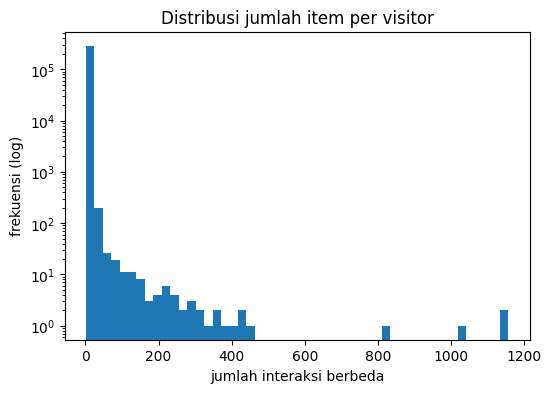

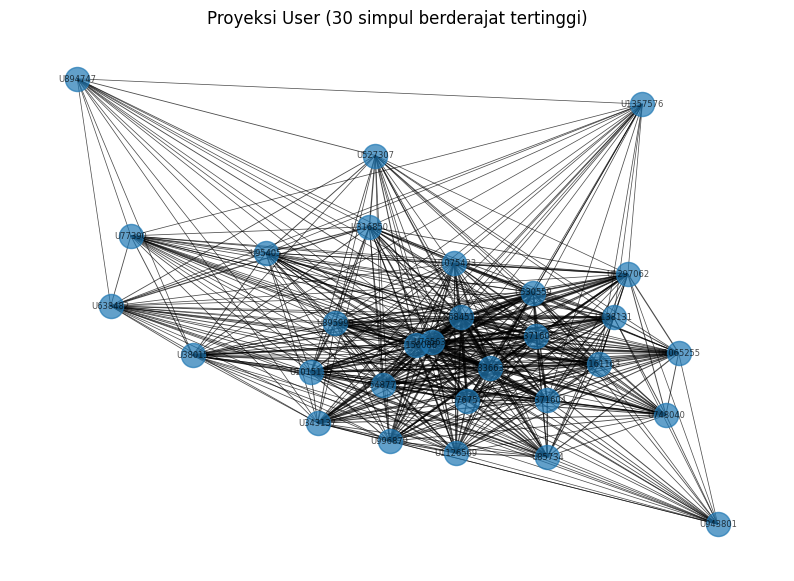

{'simpul': 30, 'busur': 407, 'density': 0.9356321839080459}


In [13]:
display(pd.DataFrame([karakteristik("User", X_user)]).set_index("VSM").T)
plot_distribusi(X_user, "Distribusi jumlah item per visitor")
plot_proyeksi("User")

### No. 4 — Karakteristik VSM User (Visitor)

| Karakteristik | Nilai |
|---|---|
| Shape matriks | 288.382 × 112.681 |
| Jumlah vektor (visitor) | 288.382 |
| Dimensi tiap vektor (= jumlah item) | 112.681 |
| Elemen non-zero (pasangan visitor–item unik) | 432.346 |
| Sparsity | 99,99867% |
| Rata-rata item per visitor | 1,50 |
| Median item per visitor | 1 |
| Maksimum item per visitor | 1.157 |
| Visitor dengan hanya 1 item | 80,49% |

**Uraian:**
1. **Dimensi dan shape**: setiap visitor direpresentasikan sebagai vektor biner berdimensi 112.681 (sebanyak item unik di P1), sehingga matriks VSM User berukuran 288.382 × 112.681.
2. **Sangat sparse**: dari sekitar 32,5 miliar sel, hanya 432.346 yang bernilai 1 (sparsity 99,99867%). Rata-rata visitor hanya berinteraksi dengan 1,5 item, dan mediannya 1.
3. **Mayoritas vektor hampir kosong**: 80,49% visitor hanya berinteraksi dengan 1 item. Vektor dengan satu elemen non-zero hampir selalu ortogonal terhadap vektor lain (cosine = 0), sehingga similarity antar-user menjadi tidak informatif.
4. **Distribusi berekor panjang (heavy-tailed)**: histogram skala log menunjukkan frekuensi yang menurun tajam. Sebagian kecil visitor sangat aktif (maksimum 1.157 item berbeda dalam 4 minggu), yang kemungkinan besar merupakan bot/crawler, bukan perilaku pembeli wajar.
5. **Plot networkx (proyeksi User)**: dari 30 visitor paling aktif terbentuk 407 busur dengan density 0,936 (407 dari maksimum 435 busur). Hampir semua visitor aktif saling terhubung karena melihat banyak item yang sama. Namun sampel ini tidak mewakili mayoritas visitor (80% hanya punya 1 item, sehingga di proyeksi penuh mereka akan terisolasi atau hanya terhubung lemah).

VSM,Item
shape,"(112681, 288382)"
jumlah_vektor,112681
dimensi,288382
non_zero,432346
sparsity_%,99.99867
mean_nnz,3.836902
median_nnz,2.0
max_nnz,713
vektor_1_nnz_%,49.001163


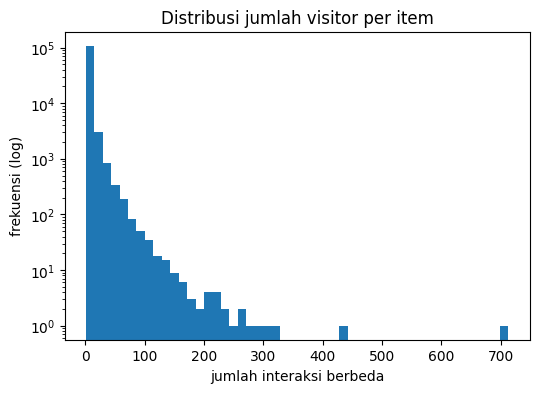

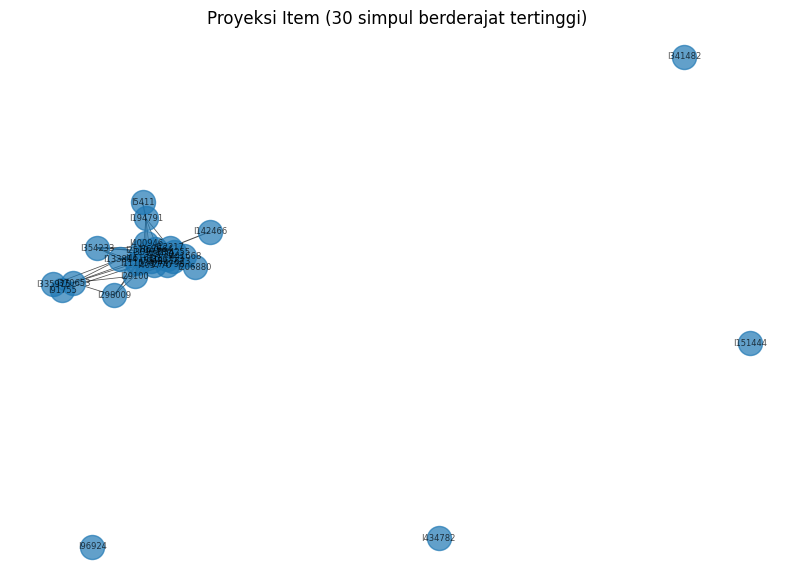

{'simpul': 30, 'busur': 165, 'density': 0.3793103448275862}


In [14]:
display(pd.DataFrame([karakteristik("Item", X_item)]).set_index("VSM").T)
plot_distribusi(X_item, "Distribusi jumlah visitor per item")
plot_proyeksi("Item")

### No. 5 — Karakteristik VSM Item

| Karakteristik | Nilai |
|---|---|
| Shape matriks | 112.681 × 288.382 |
| Jumlah vektor (item) | 112.681 |
| Dimensi tiap vektor (= jumlah visitor) | 288.382 |
| Elemen non-zero | 432.346 |
| Sparsity | 99,99867% |
| Rata-rata visitor per item | 3,84 |
| Median visitor per item | 2 |
| Maksimum visitor per item | 713 |
| Item dengan hanya 1 visitor | 49,00% |

**Uraian:**
1. **Dimensi dan shape**: VSM Item adalah transpos VSM User. Setiap item direpresentasikan sebagai vektor biner berdimensi 288.382 (sebanyak visitor unik), sehingga matriksnya berukuran 112.681 × 288.382. Jumlah elemen non-zero dan sparsity totalnya sama dengan VSM User (432.346; 99,99867%).
2. **Vektor lebih "padat" dibanding VSM User**: rata-rata item dikunjungi 3,84 visitor berbeda (median 2), sedangkan rata-rata visitor hanya 1,50 item (median 1). Proporsi vektor yang hanya punya 1 elemen non-zero juga jauh lebih kecil (49,00% dibanding 80,49%).
3. **Distribusi berekor panjang (popularity bias)**: histogram menunjukkan sebagian besar item hanya dikunjungi sedikit visitor (long-tail), sedangkan segelintir item sangat populer (maksimum 713 visitor).
4. **Plot networkx (proyeksi Item)**: dari 30 item terpopuler terbentuk 165 busur dengan density 0,379. Sebanyak 26 item membentuk satu klaster yang terhubung rapat melalui visitor yang sama (co-visitation), yaitu pola "pengunjung yang melihat item ini juga melihat item itu" yang menjadi dasar rekomendasi item-based. Sementara itu, 4 item (141482, 151444, 96924, 434782) terisolasi: meskipun populer, pengunjungnya tidak tumpang-tindih dengan pengunjung item populer lain. Hal ini menunjukkan adanya segmen minat yang berbeda.
5. Dibanding proyeksi User (density 0,936, hampir semua terhubung karena didominasi visitor super-aktif/bot), proyeksi Item lebih **terstruktur**, karena memperlihatkan klaster dan simpul terpisah yang mencerminkan kemiripan antar-item secara lebih bermakna.

In [15]:
banding = pd.DataFrame([karakteristik("User", X_user), karakteristik("Item", X_item)]).set_index("VSM")
banding["pasangan_similarity"] = [n * (n - 1) / 2 for n in banding.jumlah_vektor]
banding["simpul_P2_dikenal_di_P1_%"] = [
    100 * len(set(p2.visitorid) & set(users)) / p2.visitorid.nunique(),
    100 * len(set(p2.itemid) & set(items)) / p2.itemid.nunique()]
display(banding.T)

for nama, M in [("User", X_user), ("Item", X_item)]:
    Mn = normalize(M)
    t0 = time.perf_counter()
    for r in range(200):
        _ = Mn @ Mn[r].T
    print(f"{nama}: rata-rata waktu 1 query similarity = {(time.perf_counter()-t0)/200*1000:.2f} ms")

VSM,User,Item
shape,"(288382, 112681)","(112681, 288382)"
jumlah_vektor,288382,112681
dimensi,112681,288382
non_zero,432346,432346
sparsity_%,99.99867,99.99867
mean_nnz,1.499213,3.836902
median_nnz,1.0,2.0
max_nnz,1157,713
vektor_1_nnz_%,80.486993,49.001163
pasangan_similarity,41581944771.0,6348447540.0


User: rata-rata waktu 1 query similarity = 5.54 ms
Item: rata-rata waktu 1 query similarity = 7.47 ms


### No. 6 — Proyeksi mana yang lebih baik (efektif/efisien)?

| Aspek | Proyeksi User | Proyeksi Item |
|---|---|---|
| Jumlah vektor | 288.382 | 112.681 |
| Dimensi vektor | 112.681 | 288.382 |
| Jumlah pasangan similarity $\binom{n}{2}$ | ≈ 41,58 miliar | ≈ 6,35 miliar |
| Rata-rata / median non-zero per vektor | 1,50 / 1 | 3,84 / 2 |
| Vektor dengan hanya 1 non-zero | 80,49% | 49,00% |
| Simpul P2 yang sudah dikenal di P1 | 5,39% | 65,08% |
| Waktu 1 query similarity (rata-rata 200 query) | 5,54 ms | 7,47 ms |
| Estimasi waktu similarity semua vektor (n × waktu/query) | ≈ 1.598 detik | ≈ 842 detik |

**Kesimpulan: proyeksi Item lebih baik**, dengan alasan:

1. **Lebih efisien secara total.** Jumlah pasangan similarity pada proyeksi Item sekitar **6,5 kali lebih sedikit** (6,35 miliar dibanding 41,58 miliar). Waktu per query item memang sedikit lebih lama (7,47 ms dibanding 5,54 ms) karena dimensi vektornya lebih besar dan vektornya lebih padat, tetapi karena jumlah vektornya jauh lebih sedikit, estimasi waktu total menghitung similarity seluruh vektor justru sekitar **1,9 kali lebih cepat** (≈ 842 detik dibanding ≈ 1.598 detik).

2. **Lebih efektif (sinyal lebih kuat).** 80,49% vektor user hanya memiliki 1 item, sehingga similarity antar-user hampir selalu 0 atau ditentukan oleh satu kebetulan. Vektor item lebih padat (median 2 visitor, dan hanya 49% yang ber-nnz 1), sehingga cosine similarity antar-item lebih bermakna. Hal ini juga terlihat pada plot networkx: proyeksi Item membentuk klaster co-visitation yang terstruktur, sedangkan proyeksi User didominasi visitor super-aktif yang saling terhubung hampir penuh (density 0,936).

3. **Lebih stabil terhadap waktu (penting untuk evaluasi P2).** Hanya **5,39%** visitor P2 yang sudah muncul di P1, sedangkan **65,08%** item P2 sudah dikenal di P1. Artinya, similarity antar-user dari P1 hampir tidak bisa dipakai untuk visitor di P2 (masalah cold start), sementara similarity antar-item dari P1 tetap relevan untuk sebagian besar item di P2.

Oleh karena itu, perhitungan similarity (no. 7) dan rekomendasi KNN (bagian 2.2) menggunakan **proyeksi Item (item-based)**.

### No. 7 — Perhitungan similarity pada graf terproyeksi (Python)

Metrik yang digunakan adalah **cosine similarity** pada vektor biner item:

$$\cos(a,b) = \frac{x_a \cdot x_b}{\lVert x_a\rVert\,\lVert x_b\rVert} = \frac{|V(a) \cap V(b)|}{\sqrt{|V(a)|\cdot|V(b)|}}$$

dengan $V(\cdot)$ himpunan visitor yang berinteraksi dengan item tersebut. Vektor dinormalisasi L2 (`sklearn.preprocessing.normalize`), sehingga cosine cukup dihitung sebagai dot product antar-baris matriks.

**Record acuan**: item dengan jumlah visitor unik terbanyak di P1, ditentukan secara deterministik. Jika ada nilai similarity yang sama, urutan ditentukan berdasarkan `itemId` menaik agar hasil Python dan Cypher identik.

In [16]:
X_item_n = normalize(X_item)
REF_ITEM = int(pairs.itemid.value_counts().idxmax())     # item acuan = item dengan visitor terbanyak
print("Item acuan:", REF_ITEM, "| jumlah visitor:", int(pairs.itemid.value_counts().max()))

def top_k_similar(item_id, k=5):
    r = int(i_idx[item_id])
    sims = (X_item_n @ X_item_n[r].T).toarray().ravel()
    sims[r] = 0
    nz = np.flatnonzero(sims > 0)
    df = pd.DataFrame({"itemId": items[nz].astype(int), "cosine": sims[nz]})
    return df.sort_values(["cosine", "itemId"], ascending=[False, True]).head(k).reset_index(drop=True)

top5_py = top_k_similar(REF_ITEM)
TOP5 = [int(x) for x in top5_py.itemId]
display(top5_py)

Item acuan: 5411 | jumlah visitor: 713


,itemId,cosine
0,33030,0.170646
1,33956,0.102988
2,358234,0.100894
3,375492,0.071455
4,459936,0.066578


**Hasil:** item acuan adalah **5411** (item dengan visitor unik terbanyak di P1, yaitu 713 visitor). Lima item dengan cosine similarity tertinggi terhadap item 5411:

| Rank | itemId | Cosine |
|---|---|---|
| 1 | 33030 | 0,1706 |
| 2 | 33956 | 0,1030 |
| 3 | 358234 | 0,1009 |
| 4 | 375492 | 0,0715 |
| 5 | 459936 | 0,0666 |

Nilai cosine relatif kecil (maksimum 0,17) karena item acuan sangat populer: penyebut $\sqrt{|V(a)|\,|V(b)|}$ menjadi besar, sedangkan visitor yang dibagi dengan item lain hanya sebagian kecil dari 713 visitor tersebut. Item 33030 paling mirip karena memiliki proporsi visitor bersama tertinggi dengan item 5411.

#### No. 7(a) — Cypher untuk 5 record dengan similarity tertinggi

Cosine biner dihitung langsung pada graf (tanpa matriks), sekaligus menjadi validasi silang hasil Python:
1. Hitung $|V(a)|$, yaitu jumlah visitor unik item acuan, sekali di awal.
2. Telusuri pola 2-hop `(a)<--(v:Visitor)-->(b)` untuk mendapatkan item lain yang berbagi visitor; `count(DISTINCT v)` = $|V(a) \cap V(b)|$. `DISTINCT` diperlukan karena satu visitor bisa memiliki beberapa busur ke item yang sama (misalnya melihat berkali-kali).
3. Hitung $|V(b)|$ untuk setiap kandidat dengan subquery `CALL (b) { ... }`.
4. Hitung cosine = common / √(degA × degB), lalu urutkan `ORDER BY cosine DESC, itemId ASC` dan ambil `LIMIT 5`.

In [18]:
CYPHER_TOP5 = """
MATCH (a:Item {itemId: $ref})<--(va:Visitor)
WITH a, count(DISTINCT va) AS degA
MATCH (a)<--(v:Visitor)-->(b:Item)
WHERE a <> b
WITH degA, b, count(DISTINCT v) AS common
CALL (b) {
    MATCH (b)<--(vb:Visitor)
    RETURN count(DISTINCT vb) AS degB
}
RETURN b.itemId AS itemId, common, degA, degB,
       toFloat(common) / sqrt(toFloat(degA) * degB) AS cosine
ORDER BY cosine DESC, itemId ASC
LIMIT 5
"""
top5_cy = q(CYPHER_TOP5, ref=REF_ITEM)
display(top5_cy)

cek = top5_py.merge(top5_cy[["itemId", "cosine"]], on="itemId", how="outer",
                    suffixes=("_python", "_cypher"))
cek["selisih"] = (cek["cosine_python"] - cek["cosine_cypher"]).abs()
display(cek)
print("Hasil Python dan Cypher identik:", bool((cek["selisih"] < 1e-9).all()))
print("\nQuery untuk Neo4j Browser:\n" + CYPHER_TOP5.replace("$ref", str(REF_ITEM)))

,itemId,common,degA,degB,cosine
0,33030,35,713,59,0.170646
1,33956,11,713,16,0.102988
2,358234,15,713,31,0.100894
3,375492,18,713,89,0.071455
4,459936,16,713,81,0.066578


,itemId,cosine_python,cosine_cypher,selisih
0,33030,0.170646,0.170646,2.775558e-17
1,33956,0.102988,0.102988,1.387779e-17
2,358234,0.100894,0.100894,0.000000e+00
3,375492,0.071455,0.071455,1.387779e-17
4,459936,0.066578,0.066578,0.000000e+00


Hasil Python dan Cypher identik: True

Query untuk Neo4j Browser:

MATCH (a:Item {itemId: 5411})<--(va:Visitor)
WITH a, count(DISTINCT va) AS degA
MATCH (a)<--(v:Visitor)-->(b:Item)
WHERE a <> b
WITH degA, b, count(DISTINCT v) AS common
CALL (b) {
    MATCH (b)<--(vb:Visitor)
    RETURN count(DISTINCT vb) AS degB
}
RETURN b.itemId AS itemId, common, degA, degB,
       toFloat(common) / sqrt(toFloat(degA) * degB) AS cosine
ORDER BY cosine DESC, itemId ASC
LIMIT 5



**Hasil 7(a):** query Cypher menghasilkan 5 item yang sama dengan nilai cosine identik terhadap perhitungan Python (selisih ≤ 3×10⁻¹⁷, hanya pembulatan floating point), sehingga perhitungan similarity terbukti konsisten di kedua sisi.

| itemId | common | degA | degB | cosine |
|---|---|---|---|---|
| 33030 | 35 | 713 | 59 | 0,1706 |
| 33956 | 11 | 713 | 16 | 0,1030 |
| 358234 | 15 | 713 | 31 | 0,1009 |
| 375492 | 18 | 713 | 89 | 0,0715 |
| 459936 | 16 | 713 | 81 | 0,0666 |

Contoh perhitungan untuk item 33030: $\cos = \frac{35}{\sqrt{713 \times 59}} = \frac{35}{205{,}10} = 0{,}1706$.

Cosine mempertimbangkan **proporsi**, bukan sekadar jumlah visitor bersama. Contohnya, item 375492 memiliki lebih banyak visitor bersama (18) dibanding item 33956 (11), tetapi cosine-nya lebih kecil (0,0715 dibanding 0,1030) karena item 375492 sendiri dikunjungi 89 visitor, sehingga visitor bersama tersebut hanya sebagian kecil dari pengunjungnya. Sebaliknya, 11 dari 16 visitor item 33956 juga mengunjungi item 5411, sehingga keterkaitannya lebih kuat.

### No. 8 — Kondisi graf sebelum dan sesudah perhitungan similarity

**Sebelum**: item acuan 5411 dan kelima item paling mirip belum memiliki relasi langsung. Keterkaitannya hanya implisit, melalui visitor yang sama (jalur 2-hop `Item <- Visitor -> Item`). Query berikut menampilkan simpul-simpul tersebut beserta relasi `SIMILAR` (jika ada) dan contoh jalur melalui visitor.

In [19]:
CYPHER_SEBELUM_SESUDAH = """
MATCH (a:Item {itemId: $ref}), (b:Item) WHERE b.itemId IN $top
OPTIONAL MATCH (a)-[s:SIMILAR]->(b)
RETURN a.itemId AS item_acuan, b.itemId AS item, s.score AS similarity
ORDER BY item
"""
display(q(CYPHER_SEBELUM_SESUDAH, ref=REF_ITEM, top=TOP5))

CYPHER_VISUAL = f"""MATCH (a:Item {{itemId: {REF_ITEM}}}), (b:Item) WHERE b.itemId IN {TOP5}
OPTIONAL MATCH (a)-[s:SIMILAR]->(b)
OPTIONAL MATCH p = (a)<--(:Visitor)-->(b)
WITH a, b, s, collect(p)[..2] AS jalur
RETURN a, b, s, jalur"""
print("Query untuk Neo4j Browser (tab Graph):\n" + CYPHER_VISUAL)

Received notification from DBMS server: <GqlStatusObject gql_status='01N51', status_description='warn: relationship type does not exist. The relationship type `SIMILAR` does not exist in database `retailrocket`. Verify that the spelling is correct.', position=<SummaryInputPosition line=3, column=23, offset=86>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 86, 'line': 3, 'column': 23}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\nMATCH (a:Item {itemId: $ref}), (b:Item) WHERE b.itemId IN $top\nOPTIONAL MATCH (a)-[s:SIMILAR]->(b)\nRETURN a.itemId AS item_acuan, b.itemId AS item, s.score AS similarity\nORDER BY item\n'
Received notification from DBMS server: <GqlStatusObject gql_status='01N52', status_description='warn:

,item_acuan,item,similarity
0,5411,33030,None
1,5411,33956,None
2,5411,358234,None
3,5411,375492,None
4,5411,459936,None


Query untuk Neo4j Browser (tab Graph):
MATCH (a:Item {itemId: 5411}), (b:Item) WHERE b.itemId IN [33030, 33956, 358234, 375492, 459936]
OPTIONAL MATCH (a)-[s:SIMILAR]->(b)
OPTIONAL MATCH p = (a)<--(:Visitor)-->(b)
WITH a, b, s, collect(p)[..2] AS jalur
RETURN a, b, s, jalur


**Hasil graf di Neo4j Browser — sebelum perhitungan similarity:**

   ![No 8 sebelum](images/no8_sebelum.png)

#### No. 7(b) — Menuliskan kembali nilai similarity ke graf

Nilai cosine hasil perhitungan Python disimpan sebagai relasi baru `(:Item)-[:SIMILAR {score, metric}]->(:Item)` dari item acuan ke kelima item paling mirip:
- `UNWIND $rows AS r` mengiterasi 5 pasangan (itemId, cosine) yang dikirim dari Python sebagai parameter.
- `MATCH` mencari simpul item acuan dan item target berdasarkan `itemId` (memanfaatkan indeks dari uniqueness constraint).
- `MERGE` membuat relasi `SIMILAR` hanya jika belum ada, sehingga sel aman dijalankan ulang tanpa menggandakan relasi.
- `SET` menyimpan nilai similarity sebagai properti `score`, beserta nama metriknya.

In [22]:
CYPHER_TULIS = """
UNWIND $rows AS r
MATCH (a:Item {itemId: $ref}), (b:Item {itemId: r.itemId})
MERGE (a)-[s:SIMILAR]->(b)
SET s.score = r.cosine, s.metric = 'cosine'
"""
summary = driver.execute_query(
    CYPHER_TULIS,
    parameters_={"rows": top5_py.to_dict("records"), "ref": REF_ITEM},
    database_=DB,
).summary
print("Relasi SIMILAR dibuat:", summary.counters.relationships_created,
      "| properti di-set:", summary.counters.properties_set)

CYPHER_CEK = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR]->(b:Item)
RETURN a.itemId AS item_acuan, b.itemId AS item, s.score AS similarity, s.metric AS metrik
ORDER BY similarity DESC
"""
display(q(CYPHER_CEK, ref=REF_ITEM))
print("Query untuk Neo4j Browser:\n" + CYPHER_CEK.replace("$ref", str(REF_ITEM)))

Relasi SIMILAR dibuat: 5 | properti di-set: 10


,item_acuan,item,similarity,metrik
0,5411,33030,0.170646,cosine
1,5411,33956,0.102988,cosine
2,5411,358234,0.100894,cosine
3,5411,375492,0.071455,cosine
4,5411,459936,0.066578,cosine


Query untuk Neo4j Browser:

MATCH (a:Item {itemId: 5411})-[s:SIMILAR]->(b:Item)
RETURN a.itemId AS item_acuan, b.itemId AS item, s.score AS similarity, s.metric AS metrik
ORDER BY similarity DESC



**Sesudah**: query yang sama persis dijalankan ulang setelah langkah 7(b). Kini terdapat relasi langsung `SIMILAR` dari item acuan 5411 ke kelima item, dengan properti `score` berisi nilai cosine. Hubungan kemiripan yang sebelumnya implisit (2-hop melalui Visitor) menjadi eksplisit (1-hop), sehingga dapat digunakan langsung untuk rekomendasi tanpa menghitung ulang.

In [23]:
display(q(CYPHER_SEBELUM_SESUDAH, ref=REF_ITEM, top=TOP5))
print("Query untuk Neo4j Browser (tab Graph):\n" + CYPHER_VISUAL)

,item_acuan,item,similarity
0,5411,33030,0.170646
1,5411,33956,0.102988
2,5411,358234,0.100894
3,5411,375492,0.071455
4,5411,459936,0.066578


Query untuk Neo4j Browser (tab Graph):
MATCH (a:Item {itemId: 5411}), (b:Item) WHERE b.itemId IN [33030, 33956, 358234, 375492, 459936]
OPTIONAL MATCH (a)-[s:SIMILAR]->(b)
OPTIONAL MATCH p = (a)<--(:Visitor)-->(b)
WITH a, b, s, collect(p)[..2] AS jalur
RETURN a, b, s, jalur


**Hasil graf di Neo4j Browser — sesudah perhitungan similarity:**

![No 8 sesudah](images/no8_sesudah.png)

## 2.2 Analytics
### No. 1 — Rekomendasi KNN untuk user acak

**Proses acak yang dapat direproduksi:**
1. Kandidat user adalah visitor yang (i) berinteraksi dengan **minimal 2 item berbeda** di P1, dan (ii) di P2 berinteraksi dengan **minimal 1 item baru** (belum dilihat di P1) yang **ada di katalog P1**. Syarat ini memastikan evaluasi Hit@5/NDCG@5 bermakna, karena item yang tidak ada di P1 mustahil direkomendasikan oleh model yang dibangun dari P1.
2. Kandidat diurutkan menaik (`sorted`) agar urutannya selalu sama.
3. User dipilih dengan `random.Random(NIM).choice(kandidat)`. Seed tetap (NIM = 23031554120) membuat proses acak menghasilkan user yang sama setiap kali notebook dijalankan.

In [25]:
p1_items = pairs.groupby("visitorid")["itemid"].apply(set)
p2_items = p2.groupby("visitorid")["itemid"].apply(set)
katalog = set(items)

def ground_truth(user):
    """Item baru di P2 (belum dilihat di P1) yang ada di katalog P1."""
    return (p2_items.get(user, set()) - p1_items.get(user, set())) & katalog

kandidat = sorted(int(u) for u in p1_items.index
                  if len(p1_items[u]) >= 2 and u in p2_items.index and len(ground_truth(u)) >= 1)
USER = random.Random(NIM).choice(kandidat)

print("Jumlah kandidat user :", len(kandidat))
print("User terpilih        :", USER)
print("Item user di P1      :", sorted(int(i) for i in p1_items[USER]))
print("Ground truth (P2)    :", sorted(int(i) for i in ground_truth(USER)))

Jumlah kandidat user : 2774
User terpilih        : 377237
Item user di P1      : [88393, 159543, 301717, 384141]
Ground truth (P2)    : [1279, 80299, 111390, 149132, 217764]


#### No. 1(a) — Skrip Python rekomendasi KNN (item-based, k = 5)

Sesuai kesimpulan no. 6, rekomendasi memakai **proyeksi Item**. Untuk setiap item $j$ yang pernah dilihat user di P1, dicari $k = 5$ tetangga terdekat berdasarkan cosine similarity (tidak termasuk item yang sudah dilihat user). Skor setiap kandidat $c$ adalah jumlah similarity dari semua item yang menjadikannya tetangga:

$$\text{skor}(c) = \sum_{j \in \text{seen}(u)} \mathbb{1}[c \in \text{KNN}_5(j)] \cdot \cos(j, c)$$

Kandidat diurutkan berdasarkan skor tertinggi (jika sama, berdasarkan `itemId`). Top-5 dipakai untuk evaluasi @5, dan **3 teratas menjadi item yang diiklankan**.

In [26]:
K = 5

def rekomendasi_knn(user, k=K, n=5):
    seen = p1_items[user]
    seen_idx = np.array([i_idx[i] for i in seen])
    skor = {}
    for it in seen:
        sims = (X_item_n @ X_item_n[int(i_idx[it])].T).toarray().ravel()
        sims[seen_idx] = 0                          # abaikan item yang sudah dilihat
        urut = np.lexsort((items, -sims))           # similarity menurun, tie -> itemId
        for j in urut[:k]:                          # k tetangga terdekat
            if sims[j] > 0:
                c = int(items[j])
                skor[c] = skor.get(c, 0) + float(sims[j])
    hasil = pd.DataFrame(list(skor.items()), columns=["itemId", "skor"])
    return hasil.sort_values(["skor", "itemId"], ascending=[False, True]).head(n).reset_index(drop=True)

rekom = rekomendasi_knn(USER)
rekom.index += 1
rekom.index.name = "rank"
display(rekom)

,itemId,skor
rank,,
1,1279,0.353553
2,360683,0.353553
3,184355,0.250000
4,96409,0.158114
5,243499,0.158114


#### No. 1(b) — 3 item yang diiklankan (k = 5)

In [27]:
IKLAN = rekom.itemId.head(3).tolist()
print(f"3 item yang diiklankan untuk user {USER} (KNN k={K}):", IKLAN)

3 item yang diiklankan untuk user 377237 (KNN k=5): [1279, 360683, 184355]


**Hasil No. 1:**
- Dari 288.382 visitor P1, terdapat **2.774 kandidat user** yang memenuhi syarat. User yang terpilih secara acak (seed = NIM) adalah **377237**.
- Di P1, user 377237 berinteraksi dengan 4 item: 88393, 159543, 301717, dan 384141.
- Untuk setiap item tersebut dicari 5 tetangga terdekat (k = 5), lalu skor kandidat dijumlahkan. Hasil top-5 rekomendasi: 1279 (0,3536), 360683 (0,3536), 184355 (0,2500), 96409 (0,1581), dan 243499 (0,1581).
- **3 item yang diiklankan** untuk user 377237: **1279, 360683, dan 184355**.

Item 1279 dan 360683 memiliki skor yang sama (0,3536); urutannya ditentukan oleh `itemId` menaik agar hasil deterministik.

### No. 2 — Evaluasi Hit@5 dan NDCG@5

Relevansi bersifat biner: $rel_i = 1$ jika item pada peringkat $i$ termasuk ground truth (item baru yang diinteraksi user di P2).

$$\text{Hit@5} = \mathbb{1}\Big[\sum_{i=1}^{5} rel_i > 0\Big]$$

$$\text{DCG@5} = \sum_{i=1}^{5} \frac{rel_i}{\log_2(i+1)}, \qquad \text{IDCG@5} = \sum_{i=1}^{\min(|GT|,5)} \frac{1}{\log_2(i+1)}, \qquad \text{NDCG@5} = \frac{\text{DCG@5}}{\text{IDCG@5}}$$

Hit@5 hanya mengukur ada atau tidaknya item relevan di top-5, sedangkan NDCG@5 juga memperhitungkan **posisi**: item relevan di peringkat atas bernilai lebih besar.

In [28]:
def hit_at_k(daftar, truth, k=5):
    return int(any(i in truth for i in daftar[:k]))

def ndcg_at_k(daftar, truth, k=5):
    rel = [1 if i in truth else 0 for i in daftar[:k]]
    dcg = sum(r / np.log2(p + 2) for p, r in enumerate(rel))
    idcg = sum(1 / np.log2(p + 2) for p in range(min(len(truth), k)))
    return dcg / idcg if idcg > 0 else 0.0

truth = ground_truth(USER)
daftar = rekom.itemId.tolist()
rincian = pd.DataFrame({"rank": range(1, len(daftar) + 1), "itemId": daftar,
                        "relevan": [int(i in truth) for i in daftar]})
rincian["log2(rank+1)"] = np.log2(rincian["rank"] + 1)
rincian["gain"] = rincian.relevan / rincian["log2(rank+1)"]
display(rincian)

idcg = sum(1 / np.log2(p + 2) for p in range(min(len(truth), 5)))
print(f"|Ground truth| = {len(truth)}")
print(f"DCG@5  = {rincian.gain.sum():.4f}")
print(f"IDCG@5 = {idcg:.4f}")
print(f"Hit@5  = {hit_at_k(daftar, truth)}")
print(f"NDCG@5 = {ndcg_at_k(daftar, truth):.4f}")

,rank,itemId,relevan,log2(rank+1),gain
0,1,1279,1,1.000000,1.0
1,2,360683,0,1.584963,0.0
2,3,184355,0,2.000000,0.0
3,4,96409,0,2.321928,0.0
4,5,243499,0,2.584963,0.0


|Ground truth| = 5
DCG@5  = 1.0000
IDCG@5 = 2.9485
Hit@5  = 1
NDCG@5 = 0.3392


**Hasil No. 2 (user 377237):**

| Rank | itemId | Relevan | log₂(rank+1) | Gain |
|---|---|---|---|---|
| 1 | 1279 | 1 | 1,0000 | 1,0000 |
| 2 | 360683 | 0 | 1,5850 | 0 |
| 3 | 184355 | 0 | 2,0000 | 0 |
| 4 | 96409 | 0 | 2,3219 | 0 |
| 5 | 243499 | 0 | 2,5850 | 0 |

- **Hit@5 = 1**, karena terdapat item relevan di dalam top-5, yaitu item **1279** yang memang diinteraksi user di P2.
- **DCG@5** $= \frac{1}{\log_2 2} = 1{,}0000$.
- **IDCG@5**: ground truth berisi 5 item, sehingga urutan ideal adalah kelima posisi teratas relevan: $1 + \frac{1}{\log_2 3} + \frac{1}{\log_2 4} + \frac{1}{\log_2 5} + \frac{1}{\log_2 6} = 2{,}9485$.
- **NDCG@5** $= \frac{1{,}0000}{2{,}9485} = 0{,}3392$.

**Interpretasi:** item relevan berhasil ditempatkan di **peringkat pertama**, yang merupakan posisi terbaik, sehingga Hit@5 bernilai maksimum. NDCG@5 tidak mencapai 1 karena hanya 1 dari 5 item ground truth yang berhasil direkomendasikan; 4 item lainnya (80299, 111390, 149132, 217764) tidak muncul di top-5. Item 1279 juga termasuk dalam **3 item yang diiklankan**, sehingga iklan untuk user ini terbukti relevan dengan perilakunya di periode berikutnya.

In [29]:
driver.close()
print("Koneksi Neo4j ditutup.")

Koneksi Neo4j ditutup.
